# Hα Flux Map - Fixed Colour Scale

Notebook version of `src/01_flux_map.py` (same data: raw Hα cube for a
given CATID from `data/raw/sami_dr3_Halpha_maps/`), with one change: the
colour scale is **fixed** (`FLUX_VMIN`-`FLUX_VMAX`) instead of
auto-scaling to each galaxy's own min/max.

**Why this matters:** auto-scaling normalises every galaxy's image to its
*own* brightest pixel, so a faint, quiescent galaxy and a bright starburst
end up looking equally "lit up" - which hides exactly the thing worth
showing: that absolute Hα flux (i.e. active star formation) genuinely
differs between galaxies above, on, and below the SFMS. A shared fixed
scale makes that difference visible at a glance, which is the point for a
side-by-side thesis figure.

Two sections below: a single-galaxy plot (edit `CATID`), and a side-by-side
comparison panel for multiple galaxies sharing one colour scale and one
colorbar (defaults to the same above/on/below-MS example CATIDs used in
`sfms_explorer.ipynb`, with their `delta_ms` pulled in as subplot titles if
that notebook has been run).

In [22]:
%matplotlib inline

import re
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Jupyter's default cwd is the notebook's own directory (sami_sf_pipeline/notebooks/).
PIPELINE_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
assert (PIPELINE_ROOT / "data" / "raw").exists(), (
    f"Couldn't find data/raw under {PIPELINE_ROOT} - "
    "run this notebook from sami_sf_pipeline/notebooks/, or adjust PIPELINE_ROOT above."
)
sys.path.insert(0, str(PIPELINE_ROOT))

from src.utils.io import read_sami_halpha_layers
from src.utils.plotting import plot_map

RAW_HALPHA_DIR = PIPELINE_ROOT / "data" / "raw" / "sami_dr3_Halpha_maps"
OUT_FIGURE_DIR = PIPELINE_ROOT / "outputs" / "figures" / "flux_maps"
CSV_DIR = PIPELINE_ROOT / "outputs" / "csv"


def find_halpha_fits(catid: int) -> Path:
    """Locate the raw 1-comp Halpha FITS file for a CATID (same matching as 01_flux_map.py)."""
    matches = sorted(RAW_HALPHA_DIR.glob(f"{catid}_*_Halpha_default_1-comp.fits"))
    if not matches:
        raise FileNotFoundError(f"No raw Halpha FITS found for CATID {catid} in {RAW_HALPHA_DIR}")
    if len(matches) > 1:
        print(f"  Warning: {len(matches)} files matched CATID {catid} - using {matches[0].name}")
    return matches[0]

## Configuration - edit this cell, then re-run it and whichever section you need below

In [23]:
CATID = 7139        # <-- single-galaxy section
LAYER = "sum"        # "sum" (summed flux) or "fit" (Gaussian fit) - same choice as 01_flux_map.py
FLUX_VMIN = 0
FLUX_VMAX = 13        # <-- tune this to your sample; see the note below the single-galaxy plot
CMAP = "YlOrRd"      # <-- matplotlib colormap name, e.g. "viridis", "inferno", "magma", "plasma"

COMPARE_CATIDS = [77967, 617665, 7139]   # <-- comparison-panel section: above, on, below MS

## Single galaxy

In [24]:
fits_path = find_halpha_fits(CATID)
flux_layers, err_layers, header, meta = read_sami_halpha_layers(str(fits_path))
flux_map = flux_layers[LAYER]

print(f"Loaded: {fits_path.name}")
print(f"  Flux range (finite pixels): {np.nanmin(flux_map):.4g} - {np.nanmax(flux_map):.4g}")
print(f"  Fixed colour scale: {FLUX_VMIN} - {FLUX_VMAX}")
if np.nanmax(flux_map) > FLUX_VMAX:
    print(
        f"  NOTE: this galaxy's peak flux ({np.nanmax(flux_map):.4g}) exceeds FLUX_VMAX "
        f"({FLUX_VMAX}) - its brightest pixels will be clipped to the top colour."
    )

OUT_FIGURE_DIR.mkdir(parents=True, exist_ok=True)
outfile = OUT_FIGURE_DIR / f"{CATID}_Halpha_{LAYER}_fixedscale.png"
plot_map(
    flux_map,
    title=f"CATID {CATID} - raw Hα flux ({LAYER})",
    outfile=str(outfile),
    vmin=FLUX_VMIN, vmax=FLUX_VMAX, cmap=CMAP,
)
print(f"Saved -> {outfile}")

Loaded: 7139_A_Halpha_default_1-comp.fits
  Flux range (finite pixels): 7.887e-05 - 0.2862
  Fixed colour scale: 0 - 13
Saved -> /Users/sophiesinclair/Desktop/sami copy/sami_sf_pipeline/outputs/figures/flux_maps/7139_Halpha_sum_fixedscale.png


**On choosing `FLUX_VMAX`:** it needs to comfortably cover your brightest
example galaxy's peak flux, or that galaxy's core gets clipped to a flat
top colour (the NOTE above will warn you if that happens for the current
`CATID`). 25 works for the default `COMPARE_CATIDS` below - their peak
fluxes range from ~0.3 (CATID 7139) to ~12.7 (CATID 77967) - but re-check it
if you swap in different galaxies (CATID 6821 was the original above-MS
example but its peak flux, ~42, washed out the fainter panels next to it -
77967 was chosen as a replacement with a comparable delta_ms but much lower
peak flux).

## Comparison panel (e.g. above / on / below the SFMS)

All panels share `FLUX_VMIN`/`FLUX_VMAX` from the config cell and one
colorbar, so relative brightness between galaxies is directly comparable -
not just structure within each galaxy's own map.

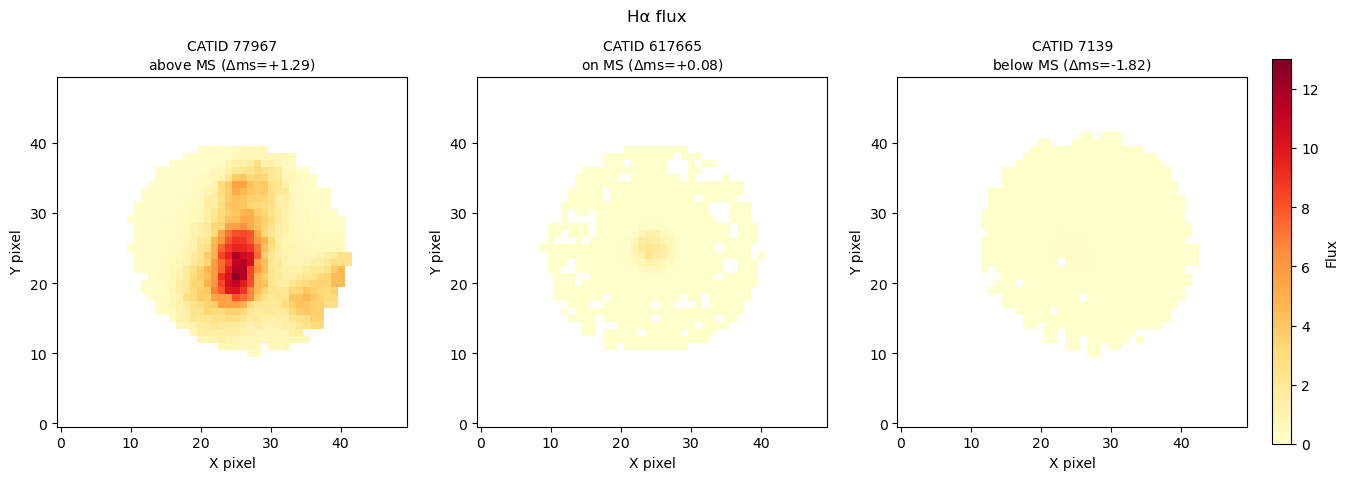

Saved -> /Users/sophiesinclair/Desktop/sami copy/sami_sf_pipeline/outputs/figures/flux_maps/sfms_comparison_flux_maps.png


In [25]:
# Optional: label each panel with its SFMS position, if sfms_explorer.ipynb has been run.
MASTER_SFMS_PATTERN = re.compile(r"^master_sfms_(\d{4}-\d{2}-\d{2})\.csv$")
sfms_candidates = sorted(p for p in CSV_DIR.glob("master_sfms_*.csv") if MASTER_SFMS_PATTERN.match(p.name))

sfms_lookup = {}
if sfms_candidates:
    master_sfms = pd.read_csv(sfms_candidates[-1])
    SFMS_BAND_DEX = 0.3
    for _, row in master_sfms.iterrows():
        dm = row.get("delta_ms", np.nan)
        if pd.isna(dm):
            continue
        elif dm > SFMS_BAND_DEX:
            label = f"above MS ($\\Delta$ms={dm:+.2f})"
        elif dm < -SFMS_BAND_DEX:
            label = f"below MS ($\\Delta$ms={dm:+.2f})"
        else:
            label = f"on MS ($\\Delta$ms={dm:+.2f})"
        sfms_lookup[int(row["CATID"])] = label
else:
    print("No master_sfms_<date>.csv found - panel titles will show CATID only. Run 05_sfms.py for delta_ms labels.")

fig, axes = plt.subplots(1, len(COMPARE_CATIDS), figsize=(5 * len(COMPARE_CATIDS) + 1, 5))
if len(COMPARE_CATIDS) == 1:
    axes = [axes]

im = None
for ax, catid in zip(axes, COMPARE_CATIDS):
    fits_path = find_halpha_fits(catid)
    flux_layers, _, _, _ = read_sami_halpha_layers(str(fits_path))
    flux_map = flux_layers[LAYER]
    if np.nanmax(flux_map) > FLUX_VMAX:
        print(f"  NOTE: CATID {catid} peak flux ({np.nanmax(flux_map):.4g}) exceeds FLUX_VMAX ({FLUX_VMAX}) - will be clipped.")
    im = plot_map(flux_map, vmin=FLUX_VMIN, vmax=FLUX_VMAX, cmap=CMAP, ax=ax)
    subtitle = f"\n{sfms_lookup[catid]}" if catid in sfms_lookup else ""
    ax.set_title(f"CATID {catid}{subtitle}", fontsize=10)

fig.suptitle(f"Hα flux", fontsize=12)
fig.colorbar(im, ax=axes, fraction=0.02, pad=0.02, label="Flux")

compare_outfile = OUT_FIGURE_DIR / "sfms_comparison_flux_maps.png"
OUT_FIGURE_DIR.mkdir(parents=True, exist_ok=True)
fig.savefig(compare_outfile, dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved -> {compare_outfile}")